# 03 · Center of gravity

**Question:** which country produced the largest share of each generation of chemists, and when did leadership change hands?

**Method** (`chemkg.cohorts`)
- Unit: birth decade. Each person counts toward the modern successor of each citizenship component, weighted 1/k for k components.
- **Leader** per decade: the largest share in a centred 3-decade rolling window. A **handoff** needs the new leader to hold the top spot for at least 2 consecutive decades (hysteresis), so near-ties don't flap. Decades with fewer than 30 people in the window are flagged as low-n.
- **Geographic center:** the spherical mean of birthplace coordinates (citizenship country's point when the birthplace is unknown).

**Assumption:** historical states are attributed to their *primary* modern successor (Prussia → Germany, Austria-Hungary → Austria).

In [1]:
import json, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from chemkg.data import load, analysable
from chemkg import countries
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 70)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
ds = load()
P, A = ds.people, analysable(ds.people)
NAMES = countries.load_iso3().set_index("iso3").name.to_dict()
print(f"{len(P):,} people, {len(A):,} analysable; enrichment loaded: {ds.enriched}")

11,903 people, 11,860 analysable; enrichment loaded: True


In [2]:
from chemkg import cohorts
counts, shares = cohorts.decade_shares(ds)
lead = cohorts.leaders(counts)
hand = cohorts.handoffs(lead)
pd.DataFrame(hand).assign(**{"from": lambda d: d["from"].map(NAMES), "to": lambda d: d["to"].map(NAMES)})

,decade,from,to,to_share
0,1810,France,Germany,0.253351
1,1860,Germany,United States,0.235119


In [3]:
lead.assign(leader=lead.leader.map(NAMES), runner_up=lead.runner_up.map(NAMES)).iloc[::2]

,leader,leader_share,runner_up,runner_up_share,n_window,low_n
decade,,,,,,
1700,France,0.310345,Germany,0.224138,29.0,True
1720,France,0.375000,United Kingdom,0.226190,84.0,False
1740,France,0.313869,United Kingdom,0.237226,137.0,False
1760,United Kingdom,0.277778,France,0.254386,171.0,False
1780,United Kingdom,0.262019,Germany,0.252404,208.0,False
1800,United Kingdom,0.256061,Germany,0.250000,330.0,False
1820,Germany,0.260349,United Kingdom,0.209150,459.0,False
1840,Germany,0.279365,United States,0.178571,630.0,False
1860,United States,0.235119,Germany,0.230283,896.0,False


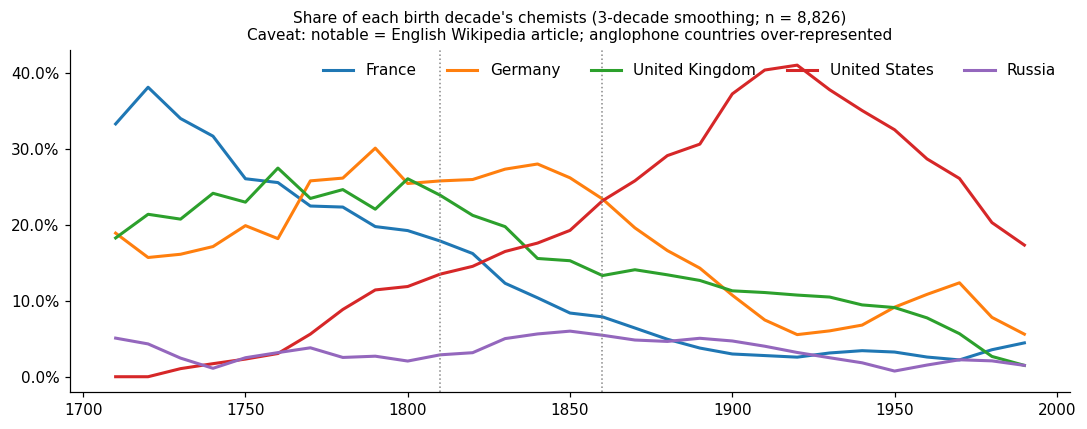

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
keys = ["FRA", "DEU", "GBR", "USA", "RUS"]
sm = shares[keys].rolling(3, center=True, min_periods=1).mean()
sm = sm[counts.sum(axis=1).rolling(3, center=True, min_periods=1).sum() >= 30]
for k in keys: ax.plot(sm.index, sm[k], label=NAMES[k], lw=2)
for h in hand: ax.axvline(h["decade"], color="#888", lw=1, ls=":")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0)); ax.legend(frameon=False, ncol=5)
ax.set_title(f"Share of each birth decade's chemists (3-decade smoothing; n = {int(counts.sum().sum()):,})\nCaveat: notable = English Wikipedia article; anglophone countries over-represented", fontsize=10)
plt.tight_layout()

In [5]:
center = cohorts.geographic_center(ds)
center.iloc[::5]

,decade,lat,lon,n
0,1700,51.411992,6.705289,15
5,1750,50.379798,4.921199,56
10,1800,53.555455,-1.960408,87
15,1850,56.361262,-3.590691,276
20,1900,64.307232,-16.745015,634
25,1950,62.303674,-9.064910,901


### Reading the result
- France leads the 18th-century cohorts, the German states lead from the 1810s, and the United States overtakes Germany in the 1860s birth cohort.
- The US peaks at about 40% of chemists born in the 1910s, then falls: Germany recovers somewhat, and India rises to about 8% of the 1970s cohort.
- Japan and China stay under 3% of every cohort. That reflects English-Wikipedia coverage, not the real size of East Asian chemistry, and it is the clearest sign of the dataset's bias.
- The geographic center moves from central Europe into the North Atlantic. That's what a mean of two continents does, and it is the clearest single picture of the shift.